# 07 · Building a Transformer: Attention and Feed-Forward Networks

In 2017, *"Attention Is All You Need"* (Vaswani et al.) removed recurrence entirely. A transformer is a stack of identical blocks, each made of just two sub-layers:

1. **Multi-head self-attention:** every token gathers information from every other token (communication).
2. **Feed-forward network (MLP):** every token processes what it gathered, independently (computation).

Both are wrapped in **residual connections** and **layer normalisation**. This notebook builds each piece from scratch, first in NumPy to see every number, then in PyTorch to train a real model and watch how attention propagates information through the layers.

**Contents**
1. Why transformers?
2. Token embeddings and positional encodings
3. Scaled dot-product attention, step by step
4. Masks: causal and padding
5. Multi-head attention
6. The feed-forward network (MLP)
7. Residual stream and LayerNorm: a full transformer block
8. A complete encoder-decoder transformer in PyTorch, trained to sort numbers
9. How attention propagates: per-layer maps, attention rollout and gradient saliency
10. Where the parameters live, and what modern transformers changed
11. Exercises

In [1]:
import warnings
warnings.filterwarnings("ignore")
import math, time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

np.random.seed(0); torch.manual_seed(0)
np.set_printoptions(precision=3, suppress=True)

def softmax(x, axis=-1):
    x = x - x.max(axis=axis, keepdims=True)
    e = np.exp(x)
    return e / e.sum(axis=axis, keepdims=True)

def show_matrix(ax, M, xlabels, ylabels, title, cmap="Blues", vmin=None, vmax=None):
    ax.imshow(M, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(xlabels))); ax.set_xticklabels(xlabels, rotation=45, ha="right")
    ax.set_yticks(range(len(ylabels))); ax.set_yticklabels(ylabels)
    ax.set_title(title, fontsize=10)

## 1. Why transformers?

| | RNN (notebook 05) | Transformer |
|---|---|---|
| How token *i* sees token *j* | through $|i-j|$ recurrent steps | **directly**, in one attention step |
| Training parallelism | sequential over time | all positions at once (GPU friendly) |
| Long-range dependencies | gradients vanish over many steps | path length 1 |
| Cost per layer | $O(n\,d^2)$ | $O(n^2 d)$ (attention) + $O(n\,d^2)$ (MLP) |

The quadratic cost in sequence length $n$ is the price; parallelism and direct connections are the reward. That trade made it possible to train on trillions of tokens, which is what GPT (notebook 08) does.

## 2. Token embeddings and positional encodings

Text is split into **tokens**, each mapped to an integer id, and each id to a learned vector of size $d_{model}$ by an **embedding table** (a matrix with one row per token).

Attention by itself has no notion of order: it treats the input as a *set*. We prove it below. So we **add** a positional signal to each embedding. The original paper used fixed sinusoids at geometrically spaced frequencies:

$$ PE_{(pos,\,2i)} = \sin\!\left(\frac{pos}{10000^{2i/d}}\right), \qquad PE_{(pos,\,2i+1)} = \cos\!\left(\frac{pos}{10000^{2i/d}}\right) $$

Low dimensions oscillate fast (fine position), high dimensions slowly (coarse position), like the hands of a clock. A useful property: the dot product $PE_{pos}\cdot PE_{pos+k}$ depends only on the offset $k$, making relative positions easy to detect.

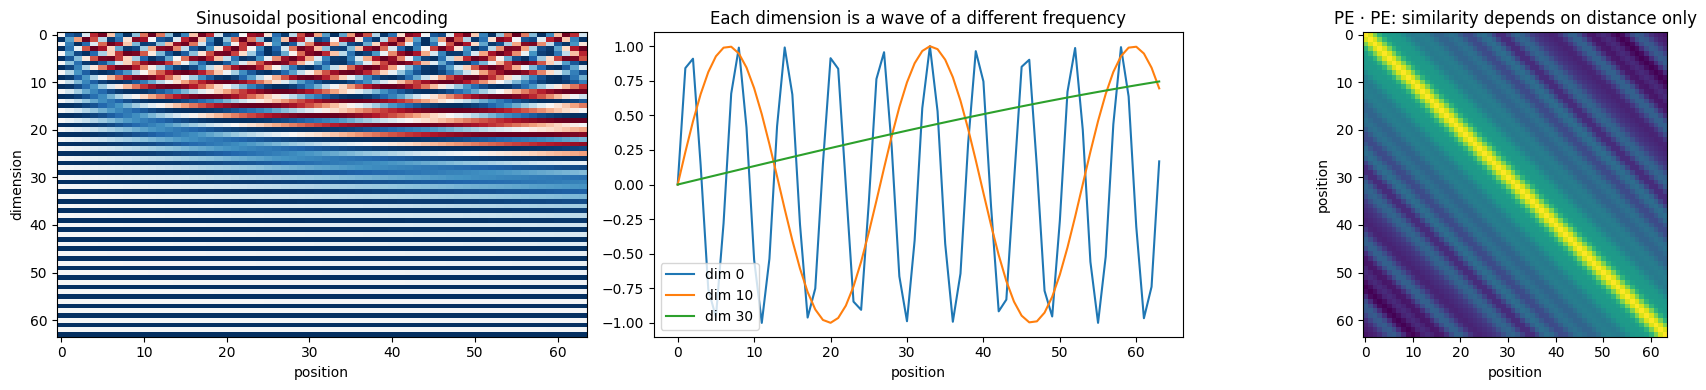

In [2]:
def sinusoidal_pe(n_pos, d):
    pos = np.arange(n_pos)[:, None]
    i = np.arange(0, d, 2)[None, :]
    angle = pos / (10000 ** (i / d))
    pe = np.zeros((n_pos, d))
    pe[:, 0::2], pe[:, 1::2] = np.sin(angle), np.cos(angle)
    return pe

pe = sinusoidal_pe(64, 64)
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].imshow(pe.T, cmap="RdBu", aspect="auto"); axes[0].set_xlabel("position"); axes[0].set_ylabel("dimension")
axes[0].set_title("Sinusoidal positional encoding")
for dim in [0, 10, 30]:
    axes[1].plot(pe[:, dim], label=f"dim {dim}")
axes[1].legend(); axes[1].set_xlabel("position"); axes[1].set_title("Each dimension is a wave of a different frequency")
axes[2].imshow(pe @ pe.T, cmap="viridis"); axes[2].set_title("PE · PE: similarity depends on distance only")
axes[2].set_xlabel("position"); axes[2].set_ylabel("position")
plt.tight_layout(); plt.show()

## 3. Scaled dot-product attention, step by step

Each token's vector $x_i$ is projected three ways with learned matrices:

* **Query** $q_i = x_i W_Q$: "what am I looking for?"
* **Key** $k_j = x_j W_K$: "what do I contain?" (an advertisement)
* **Value** $v_j = x_j W_V$: "what will I hand over if you pick me?"

Token $i$ compares its query with every key, turns the scores into weights with softmax, and takes the weighted average of the values:

$$ \text{Attention}(Q,K,V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V $$

It is a **soft, differentiable dictionary lookup**: instead of returning the value of the one matching key, it returns a blend weighted by how well each key matches.

Let's run it on a 6-token sentence with random weights so every intermediate is visible.

X: (6, 8)  Q,K,V: (6, 4)  scores: (6, 6)  output: (6, 4)
row sums of A: [1. 1. 1. 1. 1. 1.]


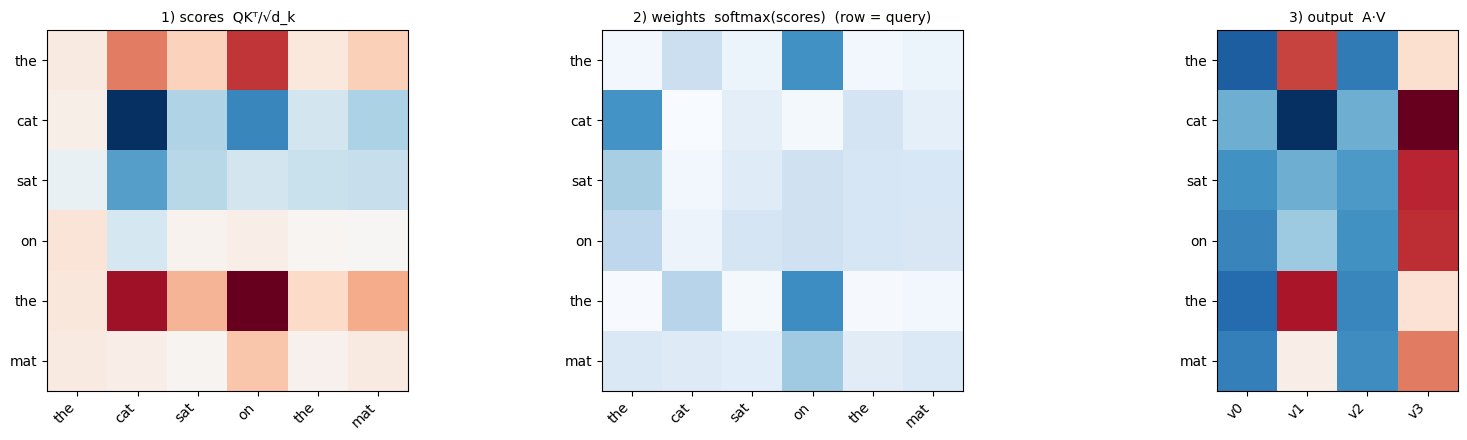

In [3]:
tokens = ["the", "cat", "sat", "on", "the", "mat"]
vocab = sorted(set(tokens))
d_model, d_k = 8, 4
E = np.random.randn(len(vocab), d_model)                     # embedding table
X = np.array([E[vocab.index(t)] for t in tokens]) + sinusoidal_pe(len(tokens), d_model)
W_Q, W_K, W_V = (np.random.randn(d_model, d_k) / np.sqrt(d_model) for _ in range(3))

Q, K, V = X @ W_Q, X @ W_K, X @ W_V
scores = Q @ K.T / np.sqrt(d_k)                              # (6, 6): every query against every key
A = softmax(scores, axis=-1)                                  # each row sums to 1
out = A @ V                                                   # (6, 4): new representation per token

print("X:", X.shape, " Q,K,V:", Q.shape, " scores:", scores.shape, " output:", out.shape)
print("row sums of A:", A.sum(axis=1))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
show_matrix(axes[0], scores, tokens, tokens, "1) scores  QKᵀ/√d_k", cmap="RdBu_r")
show_matrix(axes[1], A, tokens, tokens, "2) weights  softmax(scores)  (row = query)", vmin=0, vmax=1)
show_matrix(axes[2], out, [f"v{i}" for i in range(d_k)], tokens, "3) output  A·V", cmap="RdBu_r")
plt.tight_layout(); plt.show()

### Why divide by $\sqrt{d_k}$?

If the entries of $q$ and $k$ have unit variance, $q\cdot k$ is a sum of $d_k$ terms and has variance $d_k$. With large $d_k$ the scores become huge, softmax collapses to a one-hot vector, and its gradient becomes almost zero (the saturation problem from notebook 01). Dividing by $\sqrt{d_k}$ brings the variance back to 1.

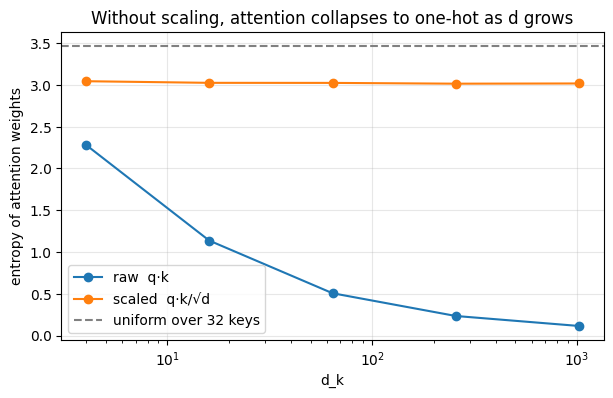

In [4]:
dims = [4, 16, 64, 256, 1024]
ent_raw, ent_scaled = [], []
for d in dims:
    q, k = np.random.randn(1000, d), np.random.randn(1000, 32, d)
    s = np.einsum("nd,nkd->nk", q, k)
    for store, ss in [(ent_raw, s), (ent_scaled, s / np.sqrt(d))]:
        p = softmax(ss)
        store.append(-(p * np.log(p + 1e-12)).sum(1).mean())
plt.figure(figsize=(7, 4))
plt.semilogx(dims, ent_raw, "o-", label="raw  q·k"); plt.semilogx(dims, ent_scaled, "o-", label="scaled  q·k/√d")
plt.axhline(np.log(32), color="gray", ls="--", label="uniform over 32 keys")
plt.xlabel("d_k"); plt.ylabel("entropy of attention weights"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Without scaling, attention collapses to one-hot as d grows"); plt.show()

### Attention without positions is order-blind

Shuffle the input tokens: the outputs are shuffled in exactly the same way, but each token's output vector is unchanged. Self-attention is **permutation-equivariant**, hence the need for positional encodings.

In [5]:
def attention(Xin):
    q, k, v = Xin @ W_Q, Xin @ W_K, Xin @ W_V
    return softmax(q @ k.T / np.sqrt(d_k)) @ v

X_nopos = np.array([E[vocab.index(t)] for t in tokens])
perm = np.random.permutation(len(tokens))
print("permutation:", perm)
print("attention(shuffled X) == shuffled attention(X):", np.allclose(attention(X_nopos[perm]), attention(X_nopos)[perm]))

permutation: [1 0 4 5 3 2]
attention(shuffled X) == shuffled attention(X): True


## 4. Masks

* **Padding mask:** sequences in a batch are padded to equal length; padded positions must not be attended to.
* **Causal (look-ahead) mask:** in a decoder or GPT, token $i$ may only attend to tokens $\le i$, otherwise it could "cheat" by looking at the word it is supposed to predict.

Both are applied by setting the forbidden scores to $-\infty$ **before** the softmax, so their weights become exactly 0.

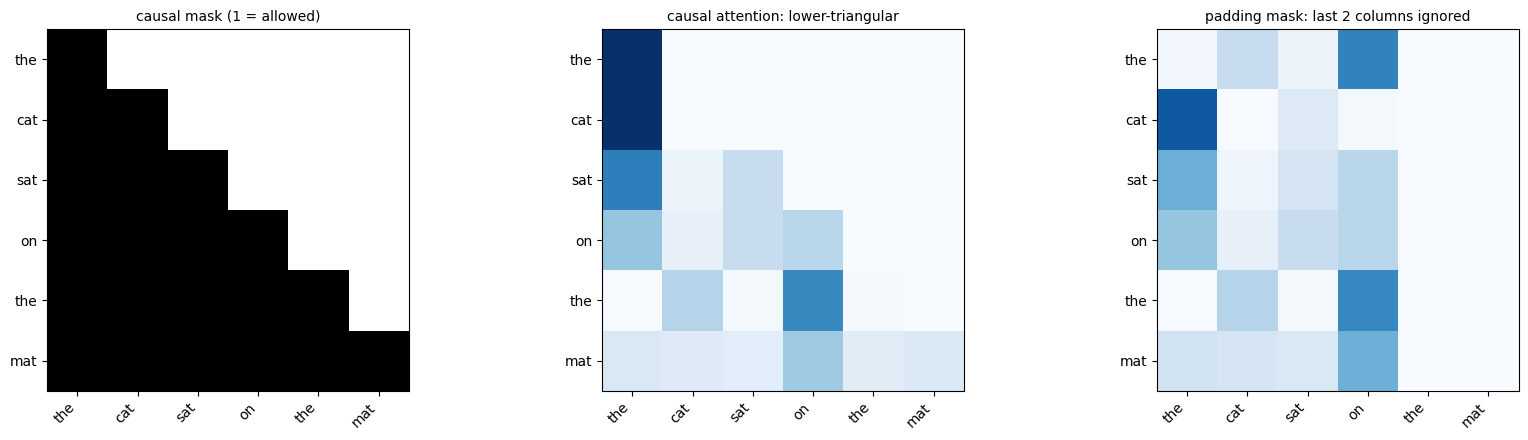

In [6]:
n = len(tokens)
causal = np.tril(np.ones((n, n), dtype=bool))
A_causal = softmax(np.where(causal, scores, -np.inf))

pad = np.array([True, True, True, True, False, False])      # pretend the last two tokens are padding
A_pad = softmax(np.where(pad[None, :], scores, -np.inf))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
show_matrix(axes[0], causal.astype(float), tokens, tokens, "causal mask (1 = allowed)", cmap="Greys")
show_matrix(axes[1], A_causal, tokens, tokens, "causal attention: lower-triangular", vmin=0, vmax=1)
show_matrix(axes[2], A_pad, tokens, tokens, "padding mask: last 2 columns ignored", vmin=0, vmax=1)
plt.tight_layout(); plt.show()

## 5. Multi-head attention

One attention pattern per layer is limiting: a token may need to look at its previous word (syntax) **and** at a related noun far away (meaning) at the same time. **Multi-head attention** runs $h$ attention operations in parallel, each in a smaller subspace of size $d_k = d_{model}/h$, then concatenates them and mixes with an output projection $W_O$:

$$ \text{MHA}(X) = \text{Concat}(\text{head}_1,\dots,\text{head}_h)\,W_O, \qquad \text{head}_i = \text{Attention}(XW_Q^{(i)}, XW_K^{(i)}, XW_V^{(i)}) $$

In practice all heads are computed with **one** big matrix multiply and a reshape, as below. Cost is the same as a single full-width head.

input (6, 8) -> output (6, 8) | attention maps (4, 6, 6) (heads, query, key)


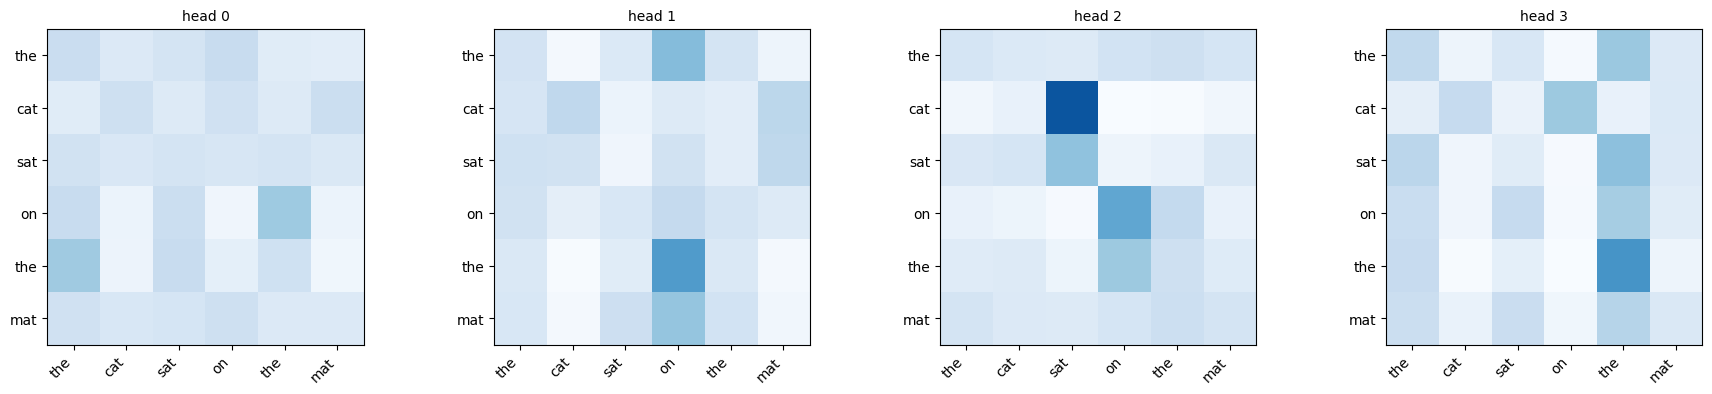

In [7]:
def multi_head_attention(X, Wq, Wk, Wv, Wo, n_heads, mask=None):
    n, d = X.shape
    dh = d // n_heads
    def split(M):                                   # (n, d) -> (heads, n, dh)
        return M.reshape(n, n_heads, dh).transpose(1, 0, 2)
    Q, K, V = split(X @ Wq), split(X @ Wk), split(X @ Wv)
    scores = Q @ K.transpose(0, 2, 1) / np.sqrt(dh)  # (heads, n, n)
    if mask is not None:
        scores = np.where(mask, scores, -np.inf)
    A = softmax(scores)
    heads = A @ V                                   # (heads, n, dh)
    concat = heads.transpose(1, 0, 2).reshape(n, d) # back to (n, d)
    return concat @ Wo, A

d_model, n_heads = 8, 4
Wq, Wk, Wv, Wo = (np.random.randn(d_model, d_model) / np.sqrt(d_model) for _ in range(4))
Y, A_heads = multi_head_attention(X, Wq, Wk, Wv, Wo, n_heads)
print("input", X.shape, "-> output", Y.shape, "| attention maps", A_heads.shape, "(heads, query, key)")
fig, axes = plt.subplots(1, n_heads, figsize=(18, 4))
for h, ax in enumerate(axes):
    show_matrix(ax, A_heads[h], tokens, tokens, f"head {h}", vmin=0, vmax=1)
plt.tight_layout(); plt.show()

## 6. The feed-forward network (MLP)

After attention has *mixed information between tokens*, each token passes **independently** through the same two-layer MLP (notebook 02), usually 4× wider in the middle:

$$ \text{FFN}(x) = W_2\,\text{GELU}(W_1 x + b_1) + b_2, \qquad W_1 \in \mathbb{R}^{4d\times d},\; W_2 \in \mathbb{R}^{d\times 4d} $$

Ways to think about it:
* **Attention = communication, MLP = computation.** Attention moves information around; the MLP transforms it.
* **Key-value memory** (Geva et al., 2021): each hidden neuron's input weights (a row of $W_1$) act as a *key* that detects a pattern; its output weights (a column of $W_2$) are the *value* written into the token when the pattern fires. Much of a language model's factual knowledge is believed to live here.
* It holds about **two thirds** of a transformer's parameters (section 10).

"Position-wise" means the same weights are applied to each token separately: the cell below checks that processing tokens one by one gives the same result as processing the whole sequence.

In [8]:
def gelu(x):
    return 0.5 * x * (1 + np.tanh(np.sqrt(2 / np.pi) * (x + 0.044715 * x ** 3)))   # GPT-2's approximation

d_ff = 4 * d_model
W1, b1 = np.random.randn(d_model, d_ff) / np.sqrt(d_model), np.zeros(d_ff)
W2, b2 = np.random.randn(d_ff, d_model) / np.sqrt(d_ff), np.zeros(d_model)
ffn = lambda x: gelu(x @ W1 + b1) @ W2 + b2

whole = ffn(X)
one_by_one = np.stack([ffn(X[i:i + 1])[0] for i in range(len(X))])
print("FFN applied to the sequence == FFN applied to each token separately:", np.allclose(whole, one_by_one))
print(f"FFN params: {W1.size + b1.size + W2.size + b2.size}  vs  attention params: {4 * d_model * d_model}")

FFN applied to the sequence == FFN applied to each token separately: True
FFN params: 552  vs  attention params: 256


## 7. Residual stream and LayerNorm: a full transformer block

Two more ingredients make deep stacks trainable:

* **Residual connections** $x \leftarrow x + \text{Sublayer}(x)$. Each sub-layer only *adds* an update to a running vector called the **residual stream**. Gradients flow straight through the additions (the same idea as the LSTM cell state and ResNet), so 100+ layers can be trained.
* **Layer normalisation** rescales each token vector to zero mean and unit variance, then applies a learned scale $\gamma$ and shift $\beta$. It keeps activations in a healthy range.

Modern models use the **pre-LN** arrangement (normalise *before* each sub-layer), which is more stable than the original post-LN:

```
x ─┬─► LayerNorm ─► Multi-Head Attention ─┐
   └──────────────────────────────────────(+)─┬─► LayerNorm ─► FFN (MLP) ─┐
                                              └───────────────────────────(+)─► next block
```

In [9]:
def layer_norm(x, gamma, beta, eps=1e-5):
    mu = x.mean(axis=-1, keepdims=True)
    var = x.var(axis=-1, keepdims=True)
    return gamma * (x - mu) / np.sqrt(var + eps) + beta

def transformer_block(x, p, mask=None):
    a, attn = multi_head_attention(layer_norm(x, *p["ln1"]), *p["attn"], n_heads=p["heads"], mask=mask)
    x = x + a                                         # residual 1: attention adds to the stream
    x = x + p["ffn"](layer_norm(x, *p["ln2"]))        # residual 2: MLP adds to the stream
    return x, attn

params = {"ln1": (np.ones(d_model), np.zeros(d_model)), "ln2": (np.ones(d_model), np.zeros(d_model)),
          "attn": (Wq, Wk, Wv, Wo), "heads": n_heads, "ffn": ffn}
h = X
for layer in range(3):                               # weight-shared for brevity; real models use different weights per layer
    h_new, _ = transformer_block(h, params, mask=causal)
    print(f"block {layer}: shape {h_new.shape}, size of update ‖Δ‖ = {np.linalg.norm(h_new - h):.2f}")
    h = h_new

# Check our LayerNorm against PyTorch's
x_t = torch.randn(5, 8)
ours = layer_norm(x_t.numpy(), np.ones(8), np.zeros(8))
print("LayerNorm matches PyTorch:", np.allclose(ours, F.layer_norm(x_t, (8,)).numpy(), atol=1e-5))

block 0: shape (6, 8), size of update ‖Δ‖ = 5.29
block 1: shape (6, 8), size of update ‖Δ‖ = 5.11
block 2: shape (6, 8), size of update ‖Δ‖ = 5.46
LayerNorm matches PyTorch: True


## 8. A complete transformer in PyTorch, trained to sort numbers

Now the real thing: an **encoder-decoder transformer** exactly as in the 2017 paper (with pre-LN), written from scratch with `nn.Linear` layers. No `nn.Transformer`. The attention modules store their weights so we can inspect them afterwards.

**Task:** input 10 random digits, output them sorted. *"3 9 1 1 7 0 4 2 8 5"* → *"0 1 1 2 3 4 5 7 8 9"*. Sorting is a good toy because:
* it **requires** attention: each output position must find the $k$-th smallest digit wherever it is,
* there are $10^{10}$ possible inputs, so the model cannot memorise; it must learn the algorithm,
* the learned attention patterns are interpretable.

```
 source digits ─► Embedding + PE ─► [Encoder block] × N ─► memory ─────────────┐
                                    (self-attention + MLP)                     │
                                                                               ▼
 <sos> + sorted[:-1] ─► Embedding + PE ─► [Decoder block] × N ─► Linear ─► softmax over digits
                                          (causal self-attn + cross-attn to memory + MLP)
```

In [10]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        assert d_model % n_heads == 0
        self.h, self.dh = n_heads, d_model // n_heads
        self.Wq, self.Wk, self.Wv, self.Wo = (nn.Linear(d_model, d_model) for _ in range(4))
        self.last_attn = None
    def forward(self, x_q, x_kv, mask=None):
        B, Tq, D = x_q.shape
        Tk = x_kv.shape[1]
        q = self.Wq(x_q).view(B, Tq, self.h, self.dh).transpose(1, 2)    # (B, h, Tq, dh)
        k = self.Wk(x_kv).view(B, Tk, self.h, self.dh).transpose(1, 2)
        v = self.Wv(x_kv).view(B, Tk, self.h, self.dh).transpose(1, 2)
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.dh)            # (B, h, Tq, Tk)
        if mask is not None:
            scores = scores.masked_fill(~mask, float("-inf"))
        attn = scores.softmax(-1)
        self.last_attn = attn.detach()
        out = (attn @ v).transpose(1, 2).reshape(B, Tq, D)
        return self.Wo(out)

class FeedForward(nn.Module):
    def __init__(self, d_model, mult=4):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_model, mult * d_model), nn.GELU(), nn.Linear(mult * d_model, d_model))
    def forward(self, x):
        return self.net(x)

class EncoderBlock(nn.Module):
    def __init__(self, d, h):
        super().__init__()
        self.ln1, self.attn, self.ln2, self.ffn = nn.LayerNorm(d), MultiHeadAttention(d, h), nn.LayerNorm(d), FeedForward(d)
    def forward(self, x):
        y = self.ln1(x)
        x = x + self.attn(y, y)
        return x + self.ffn(self.ln2(x))

class DecoderBlock(nn.Module):
    def __init__(self, d, h):
        super().__init__()
        self.ln1, self.self_attn = nn.LayerNorm(d), MultiHeadAttention(d, h)
        self.ln2, self.cross_attn = nn.LayerNorm(d), MultiHeadAttention(d, h)
        self.ln3, self.ffn = nn.LayerNorm(d), FeedForward(d)
    def forward(self, x, memory, causal_mask):
        y = self.ln1(x)
        x = x + self.self_attn(y, y, causal_mask)                  # look at previous outputs only
        x = x + self.cross_attn(self.ln2(x), memory)               # look at the encoded source
        return x + self.ffn(self.ln3(x))

class Transformer(nn.Module):
    def __init__(self, vocab, d=64, heads=4, n_enc=2, n_dec=2, max_len=32):
        super().__init__()
        self.src_emb, self.tgt_emb = nn.Embedding(vocab, d), nn.Embedding(vocab, d)
        self.register_buffer("pe", torch.tensor(sinusoidal_pe(max_len, d), dtype=torch.float32))
        self.enc = nn.ModuleList(EncoderBlock(d, heads) for _ in range(n_enc))
        self.dec = nn.ModuleList(DecoderBlock(d, heads) for _ in range(n_dec))
        self.ln_enc, self.ln_dec = nn.LayerNorm(d), nn.LayerNorm(d)
        self.out = nn.Linear(d, vocab)
        self.d = d
    def encode(self, src):
        x = self.src_emb(src) * math.sqrt(self.d) + self.pe[:src.shape[1]]
        for blk in self.enc:
            x = blk(x)
        return self.ln_enc(x)
    def decode(self, tgt_in, memory):
        T = tgt_in.shape[1]
        causal = torch.tril(torch.ones(T, T, dtype=torch.bool, device=tgt_in.device))
        x = self.tgt_emb(tgt_in) * math.sqrt(self.d) + self.pe[:T]
        for blk in self.dec:
            x = blk(x, memory, causal)
        return self.out(self.ln_dec(x))
    def forward(self, src, tgt_in):
        return self.decode(tgt_in, self.encode(src))

N_DIGITS, SEQ, SOS = 10, 10, 10
VOCAB = N_DIGITS + 1

def make_batch(B):
    src = torch.randint(0, N_DIGITS, (B, SEQ))
    tgt = src.sort(dim=1).values
    tgt_in = torch.cat([torch.full((B, 1), SOS), tgt[:, :-1]], dim=1)     # shift right: teacher forcing
    return src, tgt_in, tgt

torch.manual_seed(0)
model = Transformer(VOCAB)
print(f"parameters: {sum(p.numel() for p in model.parameters()):,}")
src, tgt_in, tgt = make_batch(2)
print("example source :", src[0].tolist())
print("decoder input  :", tgt_in[0].tolist(), "(10 = <sos>)")
print("target         :", tgt[0].tolist())

parameters: 235,851
example source : [8, 8, 5, 5, 5, 0, 6, 7, 1, 6]
decoder input  : [10, 0, 1, 5, 5, 5, 6, 6, 7, 8] (10 = <sos>)
target         : [0, 1, 5, 5, 5, 6, 6, 7, 8, 8]


step    0  loss 2.4649  (0s)


step  300  loss 0.0492  (29s)


step  600  loss 0.0290  (58s)


step  900  loss 0.0024  (86s)


step 1199  loss 0.0018  (115s)


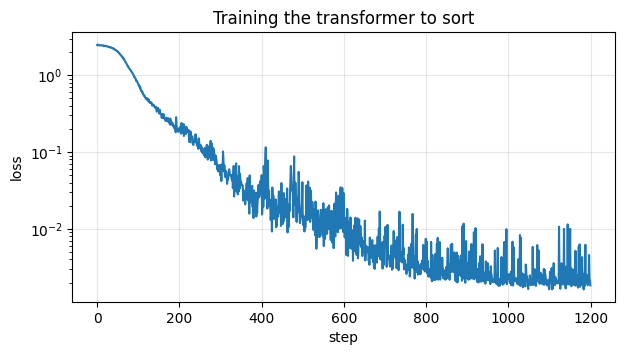

In [11]:
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.01)
steps = 1200
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=1e-3, total_steps=steps, pct_start=0.1)   # warm-up then decay
t0, losses = time.time(), []
for step in range(steps):
    src, tgt_in, tgt = make_batch(128)
    logits = model(src, tgt_in)
    loss = F.cross_entropy(logits.reshape(-1, VOCAB), tgt.reshape(-1))
    opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
    losses.append(loss.item())
    if step % 300 == 0 or step == steps - 1:
        print(f"step {step:4d}  loss {loss.item():.4f}  ({time.time() - t0:.0f}s)")
plt.figure(figsize=(7, 3.5)); plt.semilogy(losses); plt.xlabel("step"); plt.ylabel("loss"); plt.grid(alpha=0.3)
plt.title("Training the transformer to sort"); plt.show()

In [12]:
@torch.no_grad()
def greedy_sort(model, src):
    memory = model.encode(src)
    out = torch.full((src.shape[0], 1), SOS)
    for _ in range(SEQ):                                   # autoregressive: one digit at a time
        nxt = model.decode(out, memory)[:, -1].argmax(-1, keepdim=True)
        out = torch.cat([out, nxt], dim=1)
    return out[:, 1:]

model.eval()
torch.manual_seed(123)
src, _, tgt = make_batch(2000)
pred = greedy_sort(model, src)
print(f"fully correct sequences: {(pred == tgt).all(1).float().mean():.1%}   per-digit accuracy: {(pred == tgt).float().mean():.2%}")
for i in range(4):
    print("in ", src[i].tolist(), "\nout", pred[i].tolist(), "✓" if (pred[i] == tgt[i]).all() else "✗")

fully correct sequences: 99.8%   per-digit accuracy: 99.97%
in  [2, 9, 2, 0, 0, 2, 6, 7, 9, 4] 
out [0, 0, 2, 2, 2, 4, 6, 7, 9, 9] ✓
in  [1, 1, 6, 1, 2, 9, 4, 1, 3, 0] 
out [0, 1, 1, 1, 1, 2, 3, 4, 6, 9] ✓
in  [0, 6, 5, 7, 9, 2, 1, 6, 0, 6] 
out [0, 0, 1, 2, 5, 6, 6, 6, 7, 9] ✓
in  [6, 5, 3, 9, 4, 6, 1, 8, 0, 5] 
out [0, 1, 3, 4, 5, 5, 6, 6, 8, 9] ✓


## 9. How attention propagates

### 9a. What each layer and head looks at

We run one example and plot every attention map:
* **Encoder self-attention** (input ↔ input): how source tokens exchange information, e.g. to work out each digit's rank.
* **Decoder cross-attention** (output → input): for output position $k$, which source positions it reads. For sorting you should see each output step lock onto the input position(s) holding the digit it is about to write (a learned "pointer"), often with some weight on its neighbour in sorted order, which helps the model decide when to move on to the next value.

input : [7, 2, 9, 0, 4, 4, 1, 8, 3, 6] 
output: [0, 1, 2, 3, 4, 4, 6, 7, 8, 9]


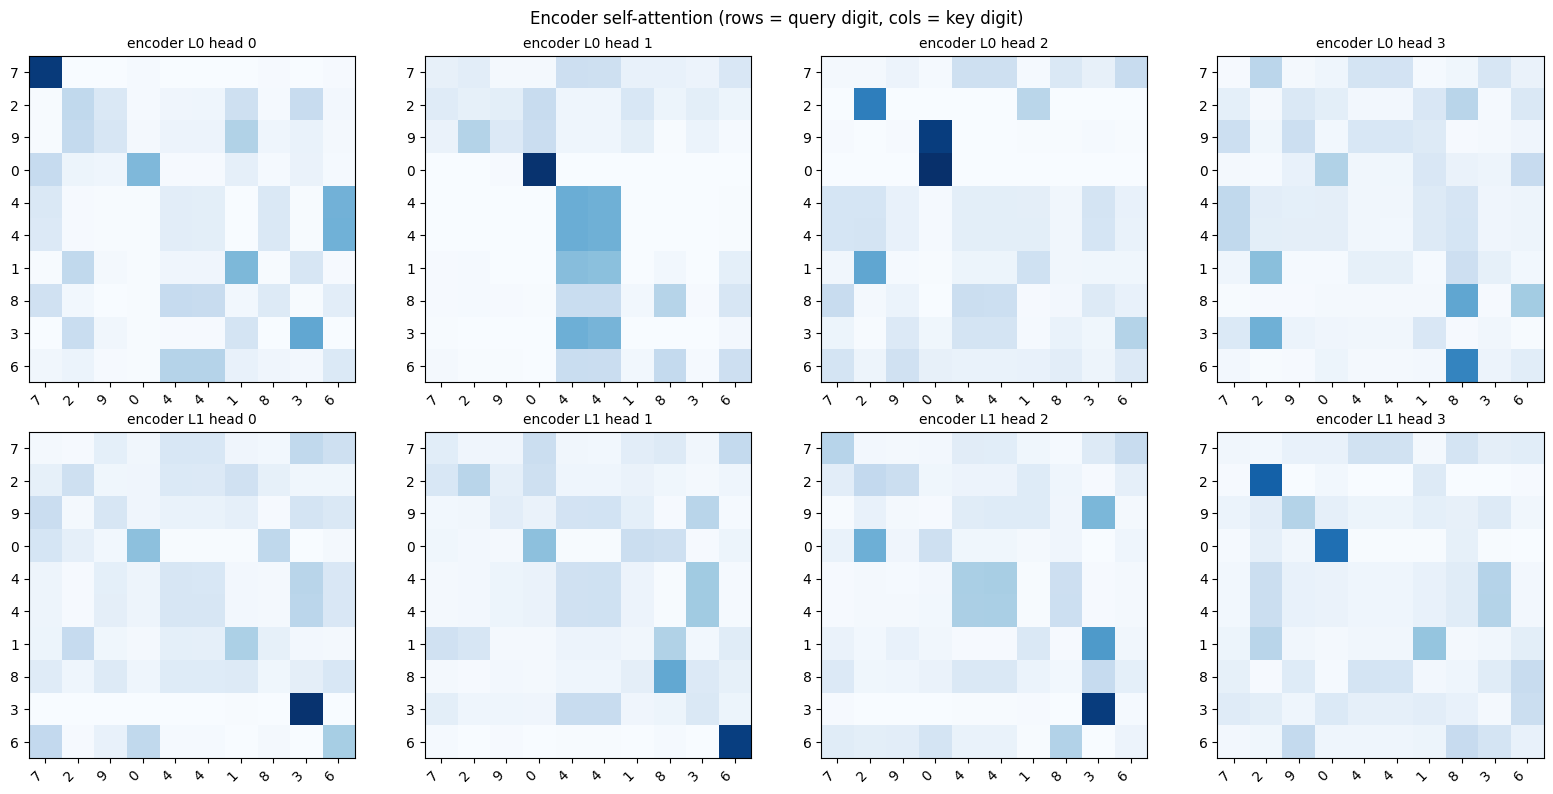

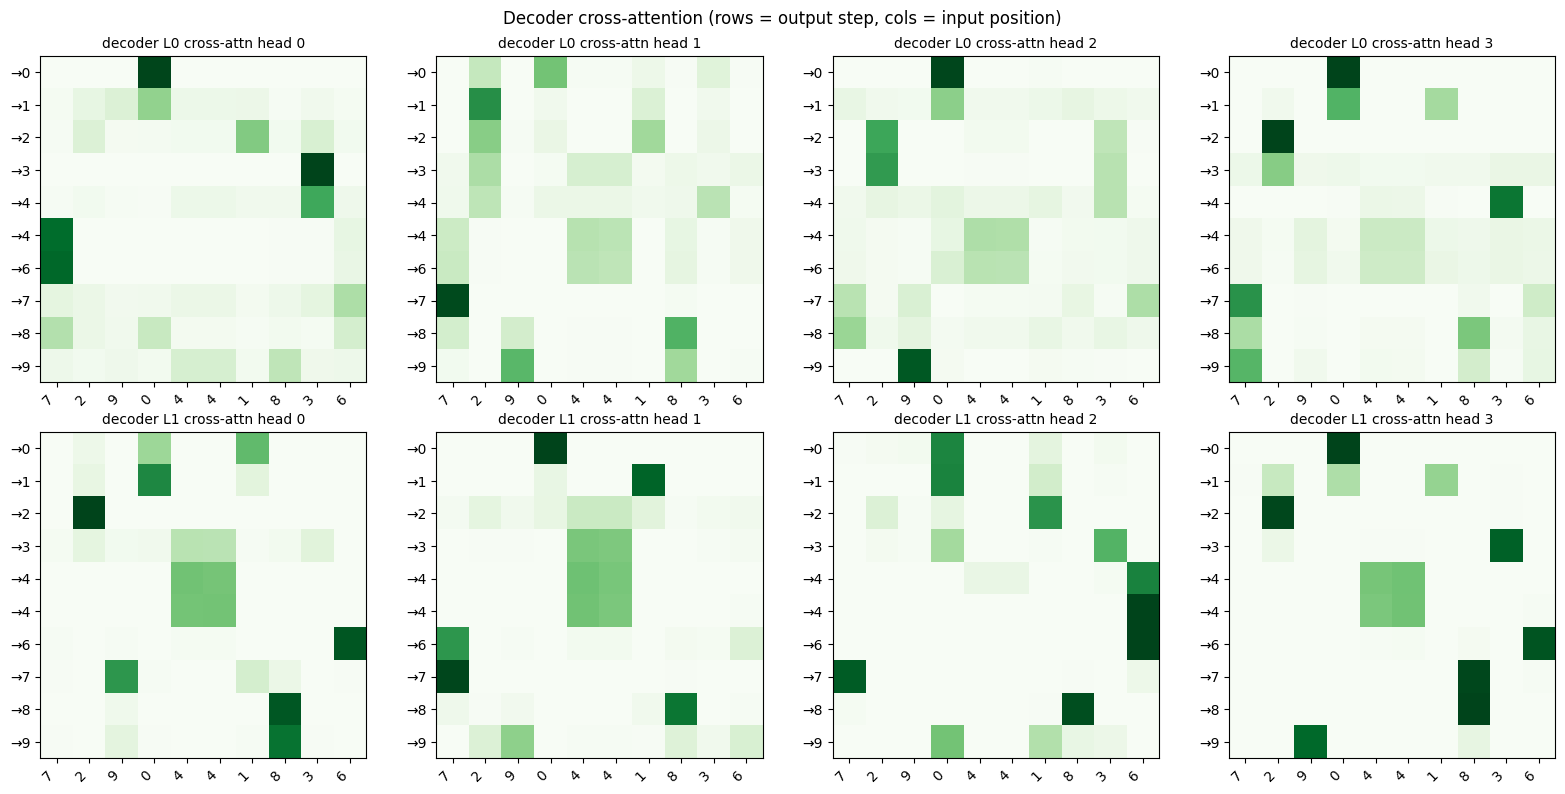

In [13]:
example = torch.tensor([[7, 2, 9, 0, 4, 4, 1, 8, 3, 6]])
with torch.no_grad():
    memory = model.encode(example)
    res = greedy_sort(model, example)
    tgt_in = torch.cat([torch.tensor([[SOS]]), res[:, :-1]], dim=1)
    model.decode(tgt_in, memory)                         # fills last_attn for the full decoded sequence
src_lbl = [f"{d}" for d in example[0].tolist()]
out_lbl = [f"→{d}" for d in res[0].tolist()]
print("input :", example[0].tolist(), "\noutput:", res[0].tolist())

H = model.enc[0].attn.h
fig, axes = plt.subplots(2, H, figsize=(4 * H, 8))
for l, blk in enumerate(model.enc):
    for h in range(H):
        show_matrix(axes[l, h], blk.attn.last_attn[0, h], src_lbl, src_lbl, f"encoder L{l} head {h}", vmin=0, vmax=1)
fig.suptitle("Encoder self-attention (rows = query digit, cols = key digit)"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, H, figsize=(4 * H, 8))
for l, blk in enumerate(model.dec):
    for h in range(H):
        show_matrix(axes[l, h], blk.cross_attn.last_attn[0, h], src_lbl, out_lbl, f"decoder L{l} cross-attn head {h}", cmap="Greens", vmin=0, vmax=1)
fig.suptitle("Decoder cross-attention (rows = output step, cols = input position)"); plt.tight_layout(); plt.show()

### 9b. Attention rollout: following information through the stack

A single attention map only shows one hop. After layer 1, token $j$'s vector already contains information from other tokens, so layer 2 attending to $j$ also indirectly reads *those* tokens. **Attention rollout** (Abnar & Zuidema, 2020) tracks this by multiplying the per-layer maps. Because of the residual connection, each layer passes on half of the original token too, which we model as $\tfrac12 A + \tfrac12 I$:

$$ R^{(L)} = \prod_{\ell=1}^{L} \left(\tfrac12 \bar A^{(\ell)} + \tfrac12 I\right) \qquad (\bar A = \text{mean over heads}) $$

Row $i$ of $R$ estimates how much of each input token has flowed into token $i$'s final representation.

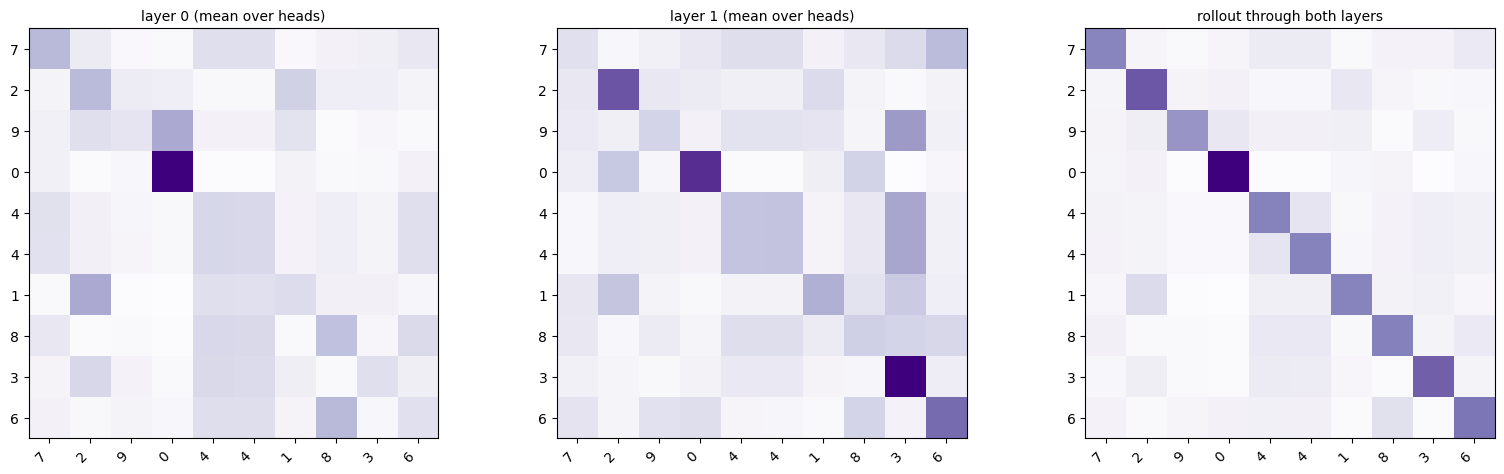

In [14]:
def rollout(attn_maps):
    R = torch.eye(attn_maps[0].shape[-1])
    for A in attn_maps:
        A_bar = A.mean(0)                                       # average heads
        A_res = 0.5 * A_bar + 0.5 * torch.eye(A_bar.shape[0])   # account for the residual path
        A_res = A_res / A_res.sum(-1, keepdim=True)
        R = A_res @ R
    return R

enc_maps = [blk.attn.last_attn[0] for blk in model.enc]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
show_matrix(axes[0], enc_maps[0].mean(0), src_lbl, src_lbl, "layer 0 (mean over heads)", cmap="Purples")
show_matrix(axes[1], enc_maps[1].mean(0), src_lbl, src_lbl, "layer 1 (mean over heads)", cmap="Purples")
show_matrix(axes[2], rollout(enc_maps), src_lbl, src_lbl, "rollout through both layers", cmap="Purples")
plt.tight_layout(); plt.show()

### 9c. Gradient flow: which inputs actually influence an output?

Attention weights tell us where information *could* flow. Gradients tell us what the output is actually *sensitive* to. We compute $\left\|\partial\, \text{logit}_k / \partial\, \text{embedding}_j\right\|$ for every output step $k$ and input position $j$. This is backpropagation (notebook 02) used for interpretation, and it flows through exactly the attention paths visualised above.

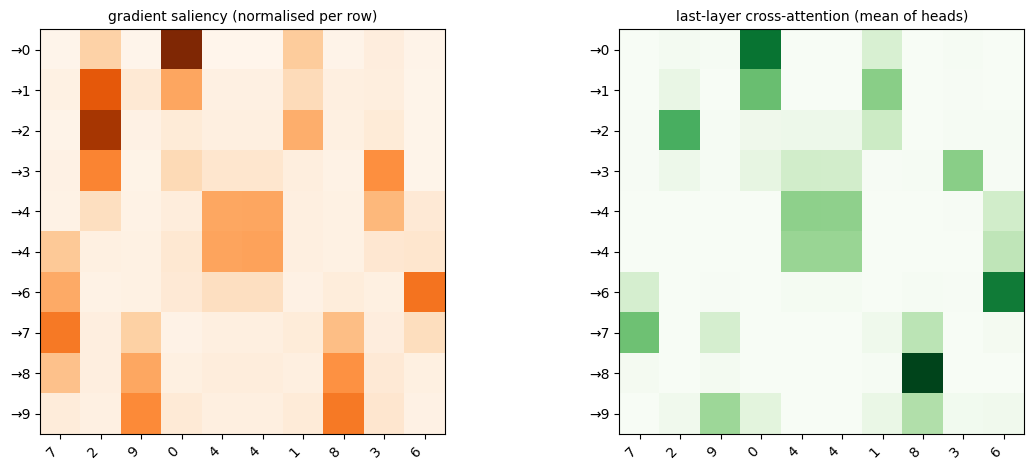

In [15]:
model.zero_grad()
emb = (model.src_emb(example) * math.sqrt(model.d)).detach().requires_grad_(True)
x = emb + model.pe[:SEQ]
for blk in model.enc:
    x = blk(x)
memory = model.ln_enc(x)
logits = model.decode(tgt_in, memory)                        # (1, SEQ, VOCAB)

saliency = torch.zeros(SEQ, SEQ)
for k in range(SEQ):
    chosen = logits[0, k, res[0, k]]                         # the logit of the digit it actually wrote
    g, = torch.autograd.grad(chosen, emb, retain_graph=True)
    saliency[k] = g[0].norm(dim=-1)
saliency = saliency / saliency.sum(1, keepdim=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
show_matrix(axes[0], saliency, src_lbl, out_lbl, "gradient saliency (normalised per row)", cmap="Oranges")
show_matrix(axes[1], model.dec[-1].cross_attn.last_attn[0].mean(0), src_lbl, out_lbl, "last-layer cross-attention (mean of heads)", cmap="Greens")
plt.tight_layout(); plt.show()

Reading the plots:
* Cross-attention and saliency largely agree: each output step depends mostly on the input holding the digit being written and on its neighbours in sorted order (the previous or next value).
* They do not agree perfectly, and that is the lesson: attention shows where information is *routed*, the gradient shows what the decision is *sensitive* to. To know that "4" comes 5th, the model must account for how many smaller digits exist; that counting happens in the encoder self-attention and the MLPs and appears as spread-out sensitivity.
* Results vary a little between training runs (different random seeds learn different but equally correct strategies).

## 10. Where the parameters live

For one block with model width $d$ and MLP expansion 4:

| Component | Parameters | Share |
|---|---|---|
| Attention $W_Q, W_K, W_V, W_O$ | $4d^2$ | ≈ 1/3 |
| Feed-forward $W_1, W_2$ | $2 \cdot d \cdot 4d = 8d^2$ | ≈ 2/3 |
| LayerNorms, biases | $O(d)$ | negligible |

So a block has about $12d^2$ parameters, the formula we will use for GPT in notebook 08.

In [16]:
def count(m): return sum(p.numel() for p in m.parameters())
blk = model.enc[0]
attn_p, ffn_p, ln_p = count(blk.attn), count(blk.ffn), count(blk.ln1) + count(blk.ln2)
print(f"encoder block (d=64): attention {attn_p:,}  FFN {ffn_p:,}  LayerNorm {ln_p:,}")
print(f"FFN share: {ffn_p / (attn_p + ffn_p + ln_p):.0%},  12·d² = {12 * 64 ** 2:,}")
for name, d, L in [("GPT-2 small", 768, 12), ("GPT-2 XL", 1600, 48), ("GPT-3", 12288, 96)]:
    print(f"{name:12s} d={d:5d} layers={L:3d}  ->  12·L·d² ≈ {12 * L * d * d / 1e9:6.2f} B parameters in the blocks")

encoder block (d=64): attention 16,640  FFN 33,088  LayerNorm 256
FFN share: 66%,  12·d² = 49,152
GPT-2 small  d=  768 layers= 12  ->  12·L·d² ≈   0.08 B parameters in the blocks
GPT-2 XL     d= 1600 layers= 48  ->  12·L·d² ≈   1.47 B parameters in the blocks
GPT-3        d=12288 layers= 96  ->  12·L·d² ≈ 173.95 B parameters in the blocks


### What modern transformers changed (and kept)

The block you built is still the core of every large model. Common upgrades since 2017:

| Original (2017) | Modern (LLaMA, Mistral, GPT-4-class models) | Why |
|---|---|---|
| Post-LN | **Pre-LN**, often **RMSNorm** | stabler training of deep stacks |
| Sinusoidal absolute positions | **RoPE** (rotary embeddings) | encodes relative position inside $q\cdot k$, extrapolates better |
| ReLU / GELU MLP | **SwiGLU** gated MLP | better quality per parameter |
| One K,V per head | **Grouped-query attention** (shared K,V) | smaller KV cache, faster generation |
| Dense MLP | **Mixture of Experts** (route each token to 2 of N MLPs) | more parameters at the same compute |
| Naive attention | **FlashAttention** (tiled, fused kernel) | same math, far less memory traffic |

## Key takeaways

* Attention = softmax$(QK^\top/\sqrt{d_k})V$: a differentiable lookup where every token can read every other token in one step.
* Multi-head attention runs several lookups in parallel subspaces; masks control who may see whom.
* The **MLP** processes each token independently and holds most parameters ("knowledge").
* **Residual connections + LayerNorm** create a residual stream that each sub-layer reads from and writes to, making deep stacks trainable.
* Attention patterns compound across layers (rollout); gradients reveal which inputs truly matter.

## Exercises

1. Remove the positional encoding from the encoder and retrain. Does sorting still work? Why might it? (Hint: is sorting order-dependent on the *input* side?) Now try a **reversal** task instead.
2. Set `heads=1` and compare accuracy and attention maps.
3. Replace `FeedForward` with a SwiGLU MLP: $W_2(\text{SiLU}(W_1x) \odot W_3x)$.
4. Train with sequences of length 10 and test on length 15 (increase `max_len`). What breaks?
5. Replace the decoder with an **encoder-only** model that predicts, at each position, the rank of that digit. Visualise its attention.